## M5 — Interpretation

Written 2026-11-22, after execution.

- **M1 — the mistake mass is concentrated and small.** 1,941 buried
  frauds (p < 0.02; 16.6% of all frauds) lose **76% of all misordered
  pairs**; the 1,176 below p < 0.01 alone lose 61%. The mistake object is
  a couple of thousand rows, not a diffuse haze.
- **M2 — no dramatic local hole.** Inside-region AUCs run 0.918 (Crypto
  Exchange) to 0.954 (Travel); nothing collapses. Calibrated against the
  pairing null (M2b), misordering concentrates genuinely **within the
  alarm side** (0.736 vs 0.580 null) and mildly within the risk block
  (0.794 vs 0.737); merchant_category and velocity block are
  chance-level. The failure is local ordering inside big regions, not
  between-pocket miscalibration.
- **M3 — the leaf arbiter is blurry at depth 6; the floor is not
  settled.** Only 11 of 1,941 buried frauds have a >= 0.9 clean
  leaf-twin, but the chance co-share is ~0.545 (the trees' dominant
  leaves hold half the fold) and observed best-twin shares cluster at
  0.63-0.89 - an ambiguous band only mildly above chance. What IS
  settled: the model retains *some* separation on most buried frauds,
  yet their best leaf-twins are also scored clean (twin p ~ 0.002-0.04).
  A sharper floor needs finer leaves (deeper model) or feature-space
  twins - named follow-up, not run here.
- **M4 — the misses are the ordinary-looking frauds.** Versus
  well-ranked frauds they are depleted in *every* risk marker: No
  Authentication 15.6% vs 52.3%, foreign 3.1% vs 25.4%, VPN 5.4% vs
  19.9%, country mismatch 3.0% vs 32.2%, new merchant 22.8% vs 56.9%;
  lower risk score (median 39 vs 49), lower velocity (22 vs 30),
  everyday merchants (Online Retail / Groceries / Restaurants over,
  Gaming / Gift Cards under). The model fails exactly where the
  generator built frauds with every multiplier near or below 1 - which
  is the multiplicative-composition picture speaking: when nothing marks
  a row, the model (correctly) scores it clean and the label disagrees.
- **Takeaway: no feature direction named.** The miss profile is an
  absence-of-signal signature, not a missing feature; FE is not
  indicated by this pass. Consistent with the bag's small gain
  (+0.001): the borderline rows benefit slightly from averaging, which
  is variance reduction, not new information.

In [1]:
from __future__ import annotations

import sys

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# features.py (CATEGORICAL_COLUMNS, prepare_features) and train_xgb.py
# (_column_lists, _xgb_features) live in experiments/baselines/, outside
# the ccf_ml package — add that folder to sys.path via the repo root so
# the notebook runs from any working directory.
from ccf_ml.file_utils import get_repo_root
sys.path.append(str(get_repo_root() / "experiments" / "baselines"))

from sklearn.metrics import roc_auc_score

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import ALARM_FLAG_COLUMNS, ID_COLUMN, TARGET_COLUMN
from ccf_ml.dataset_versions import load_dataset_version
from ccf_ml.file_utils import get_script_plot_dir, get_script_table_dir, get_train_csv_path, get_training_exp_dir
from features import CATEGORICAL_COLUMNS, prepare_features
from train_xgb import _column_lists, _xgb_features

MODEL = "xgbU_tuned_av2"
BURIED_THRESHOLDS = (0.02, 0.01)
TWIN_SHARE_FLOOR = 0.9
TOP_RANKED_P = 0.5

exp_dir = get_training_exp_dir(MODEL)
oof = pd.read_csv(exp_dir / "oof.csv")
train = pd.read_csv(get_train_csv_path())

y = oof["is_fraud"].to_numpy(dtype=bool)
p = oof["y_prob"].to_numpy(dtype=np.float64)
fold = oof["fold_id"].to_numpy(dtype=np.int64)
global_rate = float(y.mean())

plot_dir = get_script_plot_dir("mistakes_v1", section="m", group="xgbU_tuned_av2_oof_analysis")
print(f"model: {MODEL} | rows: {len(oof)} | OOF AUC: {roc_auc_score(y, p):.5f} | global rate: {global_rate:.4f}")
print("plots ->", plot_dir)

model: xgbU_tuned_av2 | rows: 699960 | OOF AUC: 0.94703 | global rate: 0.0167
plots -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\xgbU_tuned_av2_oof_analysis\mistakes_v1\plots\m


,threshold,buried frauds,share of all frauds,pairs they lose,share of all misordered pairs
0,p < 0.02,1941,0.166,325698248,0.764
1,p < 0.01,1176,0.101,261681693,0.614


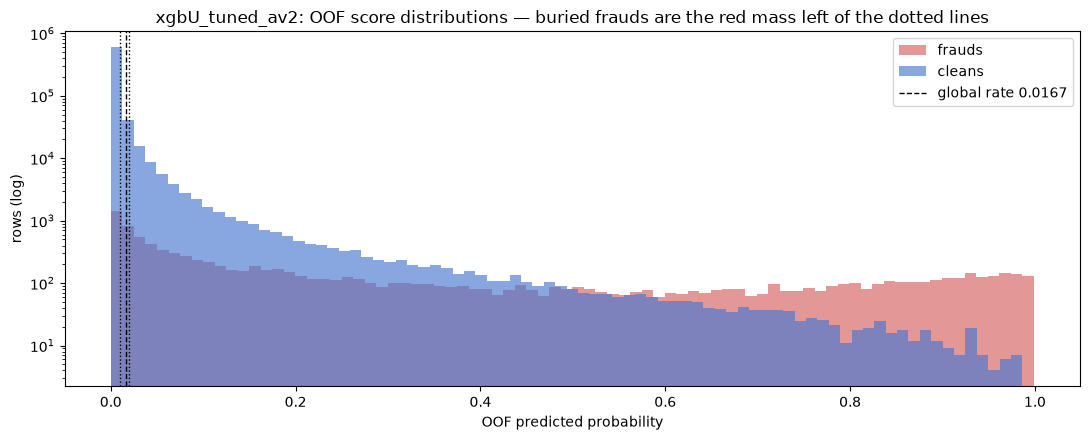

total misordered pairs: 426144057 of 8045199719


In [2]:
# M1: mistake inventory — buried frauds and the pairs they lose
n_clean = int((~y).sum())
# cleans strictly above each row = total cleans - cleans with p <= row's p
sorted_clean_p = np.sort(p[~y])
clean_above = (n_clean - np.searchsorted(sorted_clean_p, p, side="right")).astype(np.int64)

rows = []
for thr in BURIED_THRESHOLDS:
    buried = y & (p < thr)
    rows.append({
        "threshold": f"p < {thr}",
        "buried frauds": int(buried.sum()),
        "share of all frauds": round(float(buried.sum() / y.sum()), 3),
        "pairs they lose": int(clean_above[buried].sum()),
        "share of all misordered pairs": round(float(clean_above[buried].sum() / clean_above[y].sum()), 3),
    })
inv = pd.DataFrame(rows)
display(inv)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(p[y], bins=80, alpha=0.65, color="#d65f5f", label="frauds")
ax.hist(p[~y], bins=80, alpha=0.65, color="#4878d0", label="cleans")
for thr in BURIED_THRESHOLDS:
    ax.axvline(thr, color="black", ls=":", lw=1)
ax.axvline(global_rate, color="black", ls="--", lw=1, label=f"global rate {global_rate:.4f}")
ax.set_yscale("log")
ax.set_xlabel("OOF predicted probability")
ax.set_ylabel("rows (log)")
ax.set_title(f"{MODEL}: OOF score distributions — buried frauds are the red mass left of the dotted lines")
ax.legend()
fig.tight_layout()
fig.savefig(plot_dir / "m1_score_distributions.png", dpi=110)
plt.show()
print("total misordered pairs:", int(clean_above[y].sum()), "of", int(y.sum() * n_clean))

In [3]:
# M2: where ranking fails — per-region OOF AUC + within/cross misordering
alarm = alarm_flag_mask(train, columns=ALARM_FLAG_COLUMNS).to_numpy(dtype=bool)
risk_anchor = np.floor(train["merchant_risk_score"].to_numpy(float)).astype(int)
vel_anchor = np.floor(train["velocity_score"].to_numpy(float)).astype(int)

regions = {
    "alarm region": np.where(alarm, "alarm", "no-alarm"),
    "merchant_category": train["merchant_category"].to_numpy(),
    "auth_method": train["auth_method"].to_numpy(),
    "risk block": np.where(risk_anchor > 55, "high", "low"),
    "velocity block": np.where(vel_anchor > 40, "high", "low"),
}

def region_table(labels: np.ndarray) -> pd.DataFrame:
    rows = []
    for name in np.unique(labels):
        sel = labels == name
        if y[sel].sum() < 10:
            continue
        auc = roc_auc_score(y[sel], p[sel])
        own_fraud = y & (labels == name)
        rows.append({
            "region": str(name), "rows": int(sel.sum()), "frauds": int(y[sel].sum()),
            "rate": round(float(y[sel].mean()), 4),
            "OOF AUC inside": round(float(auc), 4),
            "pairs lost (all)": int(clean_above[own_fraud].sum()),
        })
    return pd.DataFrame(rows)

def within_cross(labels: np.ndarray) -> dict:
    total_within = 0
    for name in np.unique(labels):
        clean_p = np.sort(p[(~y) & (labels == name)])
        pf = p[y & (labels == name)]
        if len(pf):
            total_within += int((len(clean_p) - np.searchsorted(clean_p, pf, side="right")).sum())
    total = int(clean_above[y].sum())
    return {"within-region pairs lost": int(total_within),
            "cross-region pairs lost": total - int(total_within),
            "within share": round(total_within / total, 3)}

for name, labels in regions.items():
    print(f"\n=== {name} ===")
    display(region_table(labels))
    print(within_cross(labels))


=== alarm region ===


,region,rows,frauds,rate,OOF AUC inside,pairs lost (all)
0,alarm,53022,4758,0.0897,0.9338,60899868
1,no-alarm,646938,6931,0.0107,0.9327,365244189


{'within-region pairs lost': 313729640, 'cross-region pairs lost': 112414417, 'within share': 0.736}

=== merchant_category ===


,region,rows,frauds,rate,OOF AUC inside,pairs lost (all)
0,Crypto Exchange,5285,345,0.0653,0.9182,6083974
1,Electronics,48693,1501,0.0308,0.9291,41377331
2,Fuel,59880,741,0.0124,0.9485,31377419
3,Gaming,23784,1311,0.0551,0.9352,21949702
4,Gift Cards,9456,690,0.0730,0.9296,9683732
5,Groceries,142578,1585,0.0111,0.9478,72346768
6,Healthcare,35889,462,0.0129,0.9481,19330035
7,Online Retail,155097,1719,0.0111,0.9355,91282320
8,Restaurants,101360,1159,0.0114,0.9427,56317990
9,Streaming,47196,1061,0.0225,0.9442,33619769


{'within-region pairs lost': 50802010, 'cross-region pairs lost': 375342047, 'within share': 0.119}

=== auth_method ===


,region,rows,frauds,rate,OOF AUC inside,pairs lost (all)
0,3D Secure,210036,3098,0.0147,0.9366,133850647
1,Biometric,93666,468,0.0050,0.9369,37582541
2,No Authentication,67060,4322,0.0644,0.9299,71097407
3,OTP,175178,2464,0.0141,0.9418,101538085
4,PIN,154020,1337,0.0087,0.9327,82075377


{'within-region pairs lost': 100910804, 'cross-region pairs lost': 325233253, 'within share': 0.237}

=== risk block ===


,region,rows,frauds,rate,OOF AUC inside,pairs lost (all)
0,high,41163,2726,0.0662,0.9321,41752282
1,low,658797,8963,0.0136,0.9432,384391775


{'within-region pairs lost': 338199068, 'cross-region pairs lost': 87944989, 'within share': 0.794}

=== velocity block ===


,region,rows,frauds,rate,OOF AUC inside,pairs lost (all)
0,high,18862,1269,0.0673,0.9270,21885995
1,low,681098,10420,0.0153,0.9459,404258062


{'within-region pairs lost': 379656067, 'cross-region pairs lost': 46487990, 'within share': 0.891}


In [4]:
# M2b: calibrate the within-shares — pairing null = share of fraud-clean pairs
# that land in the same region by chance (sum of f_c * c_c). An observed
# within-share at its null means the misordering is NOT concentrated there.
rows = []
for name, labels in regions.items():
    f_share = pd.Series(labels[y]).value_counts(normalize=True)
    c_share = pd.Series(labels[~y]).value_counts(normalize=True)
    null = float(sum(f_share[c] * c_share.get(c, 0.0) for c in f_share.index))
    wc = within_cross(labels)
    rows.append({
        "region definition": name,
        "within share observed": wc["within share"],
        "pairing null": round(null, 3),
        "observed - null": round(wc["within share"] - null, 3),
        "reading": "concentrated within" if wc["within share"] - null > 0.05 else "chance-level",
    })
display(pd.DataFrame(rows))

,region definition,within share observed,pairing null,observed - null,reading
0,alarm region,0.736,0.580,0.156,concentrated within
1,merchant_category,0.119,0.107,0.012,chance-level
2,auth_method,0.237,0.197,0.040,chance-level
3,risk block,0.794,0.737,0.057,concentrated within
4,velocity block,0.891,0.871,0.020,chance-level


In [5]:
# M3: leaf-twin arbiter — can the model distinguish each buried fraud at all?
version = load_dataset_version("anchor_v2")
feature_columns, categorical_columns, _ = _column_lists(dataset_version=version)
features = _xgb_features(
    prepare_features(version.frame, feature_columns=feature_columns,
                     categorical_columns=categorical_columns),
    categorical_columns=categorical_columns,
)
ids = version.frame[ID_COLUMN].to_numpy(dtype=np.int64)
pos_by_id = np.full(int(ids.max()) + 1, -1, dtype=np.int64)
pos_by_id[ids] = np.arange(len(ids))
row_pos = pos_by_id[oof[ID_COLUMN].to_numpy(dtype=np.int64)]  # oof row -> feature row

buried = y & (p < BURIED_THRESHOLDS[0])
buried_idx = np.flatnonzero(buried)
print(f"buried frauds to arbitrate: {len(buried_idx)} (p < {BURIED_THRESHOLDS[0]})")

twin_rows = []
n_trees = None
for fold_id in range(5):
    sel_fold = fold == fold_id
    buried_in_fold = buried_idx[fold[buried_idx] == fold_id]
    if len(buried_in_fold) == 0:
        continue
    model = joblib.load(exp_dir / "models" / f"fold_{fold_id}.joblib")
    leaves = model.apply(features.iloc[row_pos[sel_fold]]).astype(np.int64)  # (n_fold, n_trees)
    n_trees = leaves.shape[1]
    fold_local = np.flatnonzero(sel_fold)
    local_of_oof = {int(g): i for i, g in enumerate(fold_local)}
    is_clean = ~y[sel_fold]
    chance = float(np.mean([
        (np.bincount(leaves[:, t]).max() / len(leaves)) for t in range(0, n_trees, 20)
    ]))
    # per-tree leaf -> local positions
    leaf_maps = []
    for t in range(n_trees):
        order_t = np.argsort(leaves[:, t], kind="stable")
        leaf_maps.append((order_t, leaves[order_t, t]))
    for gi in buried_in_fold:
        i = local_of_oof[int(gi)]
        counts = np.zeros(len(leaves), dtype=np.int32)
        for t in range(n_trees):
            order_t, sorted_leaf = leaf_maps[t]
            lo = np.searchsorted(sorted_leaf, leaves[i, t], side="left")
            hi = np.searchsorted(sorted_leaf, leaves[i, t], side="right")
            counts[order_t[lo:hi]] += 1
        counts[i] = 0
        counts[~is_clean] = 0
        best = int(counts.argmax())
        twin_rows.append({
            "oof_row": int(gi), "fold": fold_id, "p": float(p[gi]),
            "best_twin_share": round(float(counts[best] / n_trees), 3),
            "twin_p": round(float(p[fold_local[best]]), 4),
            "twins>=0.9": int((counts[is_clean] >= 0.9 * n_trees).sum()),
            "leaf chance share": round(chance, 3),
        })
twins = pd.DataFrame(twin_rows)
twins["verdict"] = np.where(twins["best_twin_share"] >= TWIN_SHARE_FLOOR, "at model floor", "true miss")
display(twins["verdict"].value_counts().rename("count").to_frame())
display(twins.head(20))
table_dir = get_script_table_dir("mistakes_v1", group="xgbU_tuned_av2_oof_analysis")
twins.to_csv(table_dir / "m3_leaf_twins.csv", index=False)
print("chance leaf-share baseline (mean max-leaf fraction, sampled trees):",
      twins["leaf chance share"].iloc[0] if len(twins) else None)

buried frauds to arbitrate: 1941 (p < 0.02)


,count
verdict,
true miss,1930
at model floor,11


,oof_row,fold,p,best_twin_share,twin_p,twins>=0.9,leaf chance share,verdict
0,2829,0,0.018743,0.762,0.0350,0,0.545,true miss
1,4055,0,0.010179,0.812,0.0140,0,0.545,true miss
2,8125,0,0.009496,0.848,0.0078,0,0.545,true miss
3,11259,0,0.007975,0.730,0.0051,0,0.545,true miss
4,15942,0,0.002900,0.875,0.0023,0,0.545,true miss
5,19281,0,0.007565,0.728,0.0065,0,0.545,true miss
6,26709,0,0.017386,0.802,0.0165,0,0.545,true miss
7,31163,0,0.015772,0.775,0.0224,0,0.545,true miss
8,36049,0,0.014380,0.795,0.0132,0,0.545,true miss
9,36443,0,0.015041,0.752,0.0432,0,0.545,true miss


chance leaf-share baseline (mean max-leaf fraction, sampled trees): 0.545


true misses: 1930 | well-ranked frauds (p > 0.5): 3676


,feature,value,share in misses,share in top frauds
0,merchant_category,Gaming,0.049,0.158
1,merchant_category,Gift Cards,0.020,0.083
2,merchant_category,Groceries,0.171,0.106
3,merchant_category,Online Retail,0.210,0.110
4,merchant_category,Restaurants,0.135,0.079
5,auth_method,3D Secure,0.319,0.217
6,auth_method,Biometric,0.082,0.021
7,auth_method,No Authentication,0.156,0.523
8,auth_method,OTP,0.249,0.170
9,auth_method,PIN,0.193,0.069


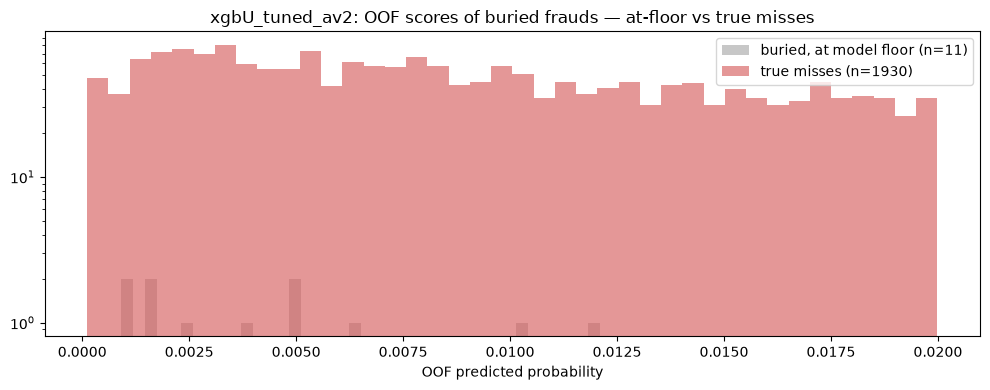

In [6]:
# M4: what the true misses look like vs well-ranked frauds (readable units)
miss_rows = twins.loc[twins["verdict"] == "true miss", "oof_row"].to_numpy()
miss = np.zeros(len(y), dtype=bool); miss[miss_rows] = True
top = y & (p > TOP_RANKED_P)
print(f"true misses: {miss.sum()} | well-ranked frauds (p > {TOP_RANKED_P}): {top.sum()}")

rows = []
for col in CATEGORICAL_COLUMNS:
    share_m = train.loc[miss, col].value_counts(normalize=True)
    share_t = train.loc[top, col].value_counts(normalize=True)
    for value in share_m.index.union(share_t.index):
        sm, st = float(share_m.get(value, 0.0)), float(share_t.get(value, 0.0))
        if max(sm, st) >= 0.05 and abs(sm - st) >= 0.05:
            rows.append({"feature": col, "value": str(value),
                         "share in misses": round(sm, 3), "share in top frauds": round(st, 3)})
for col in ["amount_usd", "merchant_risk_score", "velocity_score", "account_balance_usd",
            "customer_age", "card_age_months"]:
    rows.append({"feature": col, "value": "median",
                 "share in misses": round(float(train.loc[miss, col].median()), 2),
                 "share in top frauds": round(float(train.loc[top, col].median()), 2)})
display(pd.DataFrame(rows))

# OOF score of misses vs at-floor buried frauds
floor_rows = twins.loc[twins["verdict"] == "at model floor", "oof_row"].to_numpy()
atfloor = np.zeros(len(y), dtype=bool); atfloor[floor_rows] = True
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(p[atfloor], bins=40, alpha=0.65, color="#aaaaaa", label=f"buried, at model floor (n={atfloor.sum()})")
ax.hist(p[miss], bins=40, alpha=0.65, color="#d65f5f", label=f"true misses (n={miss.sum()})")
ax.set_yscale("log")
ax.set_xlabel("OOF predicted probability")
ax.set_title(f"{MODEL}: OOF scores of buried frauds — at-floor vs true misses")
ax.legend()
fig.tight_layout()
fig.savefig(plot_dir / "m4_misses_vs_floor.png", dpi=110)
plt.show()

## M5 — Interpretation

(filled after execution)

## M6 — the buried frauds, raw (become one with the rows)

No aggregation: the buried frauds (p < 0.02) as rows, one row each, with
their categorical profile = all categorical features + the velocity and
risk anchors. Sorted worst-first. A 30-row clean sample with the same
columns sits underneath for side-by-side eyeballing. Full table saved as
CSV. Comparison note: the model's version of this data (anchor_v2) drops
time/channel/card_type, but the display keeps every categorical so
nothing is hidden from the eye.

In [7]:
# M6: raw display — buried frauds with categorical profiles (+ clean sample)
from ccf_ml.file_utils import get_script_table_dir

CAT_COLS = ["merchant_category", "card_type", "auth_method", "channel", "device_type",
            "is_foreign_transaction", "is_new_merchant", "used_vpn",
            "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]
vel_anchor_raw = np.floor(train["velocity_score"].to_numpy(float)).astype(int)
risk_anchor_raw = np.floor(train["merchant_risk_score"].to_numpy(float)).astype(int)

buried_mask = y & (p < 0.02)
profile = pd.DataFrame({
    "id": oof["id"].to_numpy(),
    "p": np.round(p, 4),
    **{c: train[c].to_numpy() for c in CAT_COLS},
    "vel_anchor": vel_anchor_raw,
    "risk_anchor": risk_anchor_raw,
})
buried_profile = profile[buried_mask].sort_values("p")
m6_dir = get_script_table_dir("mistakes_v1", group="xgbU_tuned_av2_oof_analysis")
buried_profile.to_csv(m6_dir / "m6_buried_frauds_profiles.csv", index=False)

print(f"buried frauds (p < 0.02): {len(buried_profile)} rows — worst 100 shown; full table -> {m6_dir / 'm6_buried_frauds_profiles.csv'}")
with pd.option_context("display.max_rows", 100):
    display(buried_profile.head(100).reset_index(drop=True))

rng6 = np.random.default_rng(6)
clean_sample = profile[~y].sample(30, random_state=6).sort_values("p")
print("clean sample (30 rows, same columns, for eyeball comparison):")
display(clean_sample.reset_index(drop=True))

buried frauds (p < 0.02): 1941 rows — worst 100 shown; full table -> C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\xgbU_tuned_av2_oof_analysis\mistakes_v1\tables\m6_buried_frauds_profiles.csv


,id,p,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,vel_anchor,risk_anchor
0,226293,0.0001,Online Retail,Mastercard,No Authentication,Online,POS Terminal,False,False,False,False,False,False,0,42
1,326219,0.0001,Fuel,Visa,3D Secure,Online,Android Phone,False,False,False,False,False,False,0,46
2,608552,0.0001,Restaurants,Visa,OTP,Contactless,iPhone,False,False,False,False,False,False,32,13
3,375919,0.0001,Online Retail,Visa,Biometric,Online,POS Terminal,False,False,False,False,False,False,11,21
4,121166,0.0002,Travel,Visa,PIN,In-App,iPhone,False,False,False,False,False,False,25,24
5,405262,0.0002,Online Retail,Visa,Biometric,ATM,iPhone,False,False,False,False,False,False,21,24
6,264238,0.0002,Restaurants,Mastercard,PIN,Online,Smart Watch,False,False,False,False,False,False,11,17
7,271077,0.0002,Online Retail,Mastercard,OTP,Online,Tablet,False,False,False,False,False,False,12,28
8,653934,0.0002,Groceries,RuPay,3D Secure,In-App,Android Phone,False,False,False,False,False,False,2,32
9,1958,0.0002,Utilities,Visa,3D Secure,Online,POS Terminal,False,False,False,False,False,False,1,37


clean sample (30 rows, same columns, for eyeball comparison):


,id,p,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,vel_anchor,risk_anchor
0,32157,0.0001,Groceries,Mastercard,PIN,POS,Tablet,False,True,False,False,False,False,12,10
1,442196,0.0001,Fuel,Mastercard,3D Secure,Contactless,POS Terminal,False,False,False,False,False,False,14,21
2,673429,0.0003,Streaming,Visa,PIN,Contactless,POS Terminal,False,False,False,False,False,False,11,19
3,474692,0.0005,Groceries,Visa,No Authentication,Contactless,POS Terminal,False,False,False,False,False,False,25,28
4,660421,0.0005,Streaming,Mastercard,PIN,Contactless,Windows PC,False,False,False,False,False,False,11,31
5,433829,0.0006,Electronics,Mastercard,OTP,Contactless,iPhone,False,False,True,False,False,False,17,34
6,668825,0.0007,Fuel,Mastercard,No Authentication,Contactless,POS Terminal,False,False,False,False,False,False,19,21
7,433870,0.0008,Restaurants,Mastercard,PIN,POS,iPhone,False,False,False,False,False,False,23,36
8,596131,0.0008,Utilities,Mastercard,OTP,POS,POS Terminal,False,False,False,False,False,False,12,30
9,500741,0.0009,Travel,Visa,OTP,Online,iPhone,False,False,False,False,False,False,16,40


## M7 — similar-profile neighbors: is_alarm replaces the five alarm columns

Hypothesis under test (user): the model leans so heavily on the five
alarm flags that it under-learns easy signal available from the rest —
e.g. the worst-scored fraud sits on risk anchor 42, whose own fraud rate
exceeds 0.02, far above its predicted p.

Profile: (merchant_category, card_type, auth_method, channel,
device_type, is_alarm) plus the velocity / risk anchors. For each buried
fraud, its neighbor set is found through a fallback hierarchy (exact on
everything first, then progressively coarser), the first level whose
neighbor count (excluding the fraud itself) reaches 50 wins:

- L1: profile + risk anchor + velocity anchor, exact
- L2: profile + risk anchor, exact
- L3: profile + risk anchor ±2
- L4: profile only
- L5: (merchant_category, auth_method, is_alarm)

Readouts per buried fraud: neighbor fraud rate vs the model's p, and the
risk anchor's own marginal rate vs p. If neighbors (who share everything
except the five alarm columns) carry rates far above p, the easy signal
was available and unlearned.

levels used:
level
L4 profile         907
L3 risk±2          479
L5 merch+auth      474
L2 +risk anchor     81
buried frauds with a >= 50-neighbor group: 1941 / 1941
median neighbor rate: 0.0108 | median p: 0.00799
share with neighbor_rate >= 2x p: 43.6%
share with neighbor_rate >= 5x p: 20.8%
share with anchor_rate >= 2x p:   56.8%
share with anchor_rate >= 0.02:   37.6%


,id,p,level,neighbors,neighbor frauds,neighbor_rate,risk_anchor,anchor_rate,neighbor_rate/p,anchor_rate/p
0,226293,0.00012,L4 profile,302,3,0.0099,42,0.0173,85.4,149.0
1,326219,0.00012,L3 risk±2,67,0,0.0000,46,0.0309,0.0,250.4
2,608552,0.00014,L4 profile,404,2,0.0050,13,0.0013,36.3,9.8
3,375919,0.00014,L3 risk±2,61,0,0.0000,21,0.0020,0.0,13.6
4,1958,0.00017,L3 risk±2,68,0,0.0000,37,0.0135,0.0,80.1
5,271077,0.00018,L4 profile,199,1,0.0050,28,0.0057,27.8,31.6
6,264238,0.00019,L4 profile,91,0,0.0000,17,0.0031,0.0,16.0
7,653934,0.00019,L4 profile,79,1,0.0127,32,0.0055,66.5,29.1
8,121166,0.00021,L4 profile,95,1,0.0105,24,0.0044,50.9,21.1
9,405262,0.00023,L4 profile,89,1,0.0112,24,0.0044,48.5,18.9


buried frauds in the alarm region: 13.2% (alarm region holds 40.7% of all frauds)


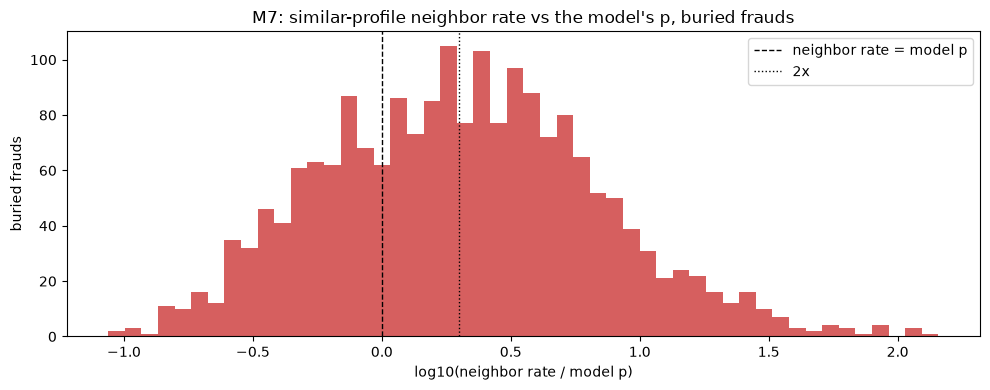

In [8]:
# M7: hierarchical similar-profile lookup for every buried fraud
cat_cols = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
cat_code = np.zeros(len(train), dtype=np.int64)
for c in cat_cols:
    cc, uniq = pd.factorize(train[c])
    cat_code = cat_code * max(len(uniq), 1) + cc.astype(np.int64)
is_alarm = alarm_flag_mask(train, columns=ALARM_FLAG_COLUMNS).to_numpy(dtype=bool)
mc_code, _ = pd.factorize(train["merchant_category"])
am_code, _ = pd.factorize(train["auth_method"])
ra_all = np.floor(train["merchant_risk_score"].to_numpy(float)).astype(int)
va_all = np.floor(train["velocity_score"].to_numpy(float)).astype(int)
yy = y.astype(np.int64)

def group_sums(keys):
    df = pd.DataFrame({"k": keys, "y": yy})
    agg = df.groupby("k")["y"].agg(f="sum", n="size")
    return {k: (int(r["f"]), int(r["n"])) for k, r in agg.iterrows()}

g_l1 = group_sums(list(zip(cat_code, is_alarm, ra_all, va_all)))
g_l2 = group_sums(list(zip(cat_code, is_alarm, ra_all)))
g_l2_arr = pd.DataFrame({"c": cat_code, "al": is_alarm, "ra": ra_all, "y": yy})     .groupby(["c", "al", "ra"])["y"].agg(f="sum", n="size").reset_index()
g_l4 = group_sums(list(zip(cat_code, is_alarm)))
g_l5 = group_sums(list(zip(mc_code, am_code, is_alarm)))
anchor_rate_full = pd.Series(yy).groupby(ra_all).mean()

# per (cat, alarm) cumulative sums over risk anchors for the ±2 windows
win = {}
for (c, al), sub in g_l2_arr.groupby(["c", "al"]):
    sub = sub.sort_values("ra")
    win[(c, al)] = (sub["ra"].to_numpy(), np.r_[0, sub["f"].cumsum().to_numpy()],
                    np.r_[0, sub["n"].cumsum().to_numpy()])

def window_l3(c, al, ra, half=2):
    ras, cf, cn = win[(c, al)]
    lo = np.searchsorted(ras, ra - half, side="left")
    hi = np.searchsorted(ras, ra + half, side="right")
    return int(cf[hi] - cf[lo]), int(cn[hi] - cn[lo])

MIN_N = 50
rows = []
for i in np.flatnonzero(y & (p < 0.02)):
    key6 = (int(cat_code[i]), bool(is_alarm[i]))
    cands = [
        ("L1 full+anchors", g_l1.get((cat_code[i], is_alarm[i], ra_all[i], va_all[i]), (0, 0))),
        ("L2 +risk anchor", g_l2.get((cat_code[i], is_alarm[i], ra_all[i]), (0, 0))),
        ("L3 risk±2", window_l3(cat_code[i], is_alarm[i], int(ra_all[i]))),
        ("L4 profile", g_l4.get(key6, (0, 0))),
        ("L5 merch+auth", g_l5.get((int(mc_code[i]), int(am_code[i]), bool(is_alarm[i])), (0, 0))),
    ]
    level, nf, nn = None, None, None
    for lev, (f, n) in cands:
        if n - 1 >= MIN_N:
            level, nf, nn = lev, f - 1, n - 1
            break
    neighbor_rate = nf / nn if (nf is not None and nn > 0) else np.nan
    anchor_rate = float(anchor_rate_full.get(int(ra_all[i]), np.nan))
    rows.append({
        "id": int(oof["id"].to_numpy()[i]), "p": round(float(p[i]), 5),
        "level": level, "neighbors": nn, "neighbor frauds": nf,
        "neighbor_rate": round(float(neighbor_rate), 4) if neighbor_rate == neighbor_rate else None,
        "risk_anchor": int(ra_all[i]), "anchor_rate": round(anchor_rate, 4),
        "neighbor_rate/p": round(float(neighbor_rate / max(p[i], 1e-6)), 1) if neighbor_rate == neighbor_rate else None,
        "anchor_rate/p": round(anchor_rate / max(p[i], 1e-6), 1),
    })
m7 = pd.DataFrame(rows)
m7_dir = get_script_table_dir("mistakes_v1", group="xgbU_tuned_av2_oof_analysis")
m7.to_csv(m7_dir / "m7_profile_neighbors.csv", index=False)

print("levels used:"); print(m7["level"].value_counts().to_string())
valid = m7.dropna(subset=["neighbor_rate"])
print(f"buried frauds with a >= {MIN_N}-neighbor group: {len(valid)} / {len(m7)}")
print(f"median neighbor rate: {valid['neighbor_rate'].median():.4f} | median p: {valid['p'].median():.5f}")
print(f"share with neighbor_rate >= 2x p: {(valid['neighbor_rate'] >= 2 * valid['p']).mean():.1%}")
print(f"share with neighbor_rate >= 5x p: {(valid['neighbor_rate'] >= 5 * valid['p']).mean():.1%}")
print(f"share with anchor_rate >= 2x p:   {(m7['anchor_rate'] >= 2 * m7['p']).mean():.1%}")
print(f"share with anchor_rate >= 0.02:   {(m7['anchor_rate'] >= 0.02).mean():.1%}")
display(m7.sort_values("p").head(25).reset_index(drop=True))

print(f"buried frauds in the alarm region: {is_alarm[y & (p < 0.02)].mean():.1%} (alarm region holds {is_alarm[y].mean():.1%} of all frauds)")

fig, ax = plt.subplots(figsize=(10, 4))
# zero-rate neighbor groups plotted at a half-count floor so log stays finite
floor = 0.5 / valid["neighbors"]
ratios = np.log10(valid["neighbor_rate"].clip(lower=floor) / valid["p"].clip(lower=1e-6))
ax.hist(ratios, bins=50, color="#d65f5f")
ax.axvline(0, color="black", ls="--", lw=1, label="neighbor rate = model p")
ax.axvline(np.log10(2), color="black", ls=":", lw=1, label="2x")
ax.set_xlabel("log10(neighbor rate / model p)")
ax.set_ylabel("buried frauds")
ax.set_title("M7: similar-profile neighbor rate vs the model's p, buried frauds")
ax.legend()
fig.tight_layout()
fig.savefig(plot_dir / "m7_neighbor_rate_vs_p.png", dpi=110)
plt.show()

### M7 reading

Written 2026-11-23, after execution.

- **The user's risk-anchor example generalizes.** 56.8% of the 1,941
  buried frauds sit on risk anchors whose own pooled rate is at least 2x
  their predicted p, and 37.6% sit on anchors rated above 0.02 — above
  their score, above the global base rate. The easy, coarse signal was
  sitting in plain view for over a third of the pile.
- **Conditioning on the non-flag profile shrinks the gap.** Similar-
  profile neighbors (is_alarm replacing the five flags; groups found via
  L1..L5 fallback, median ~ hundreds of rows) carry a median rate of
  0.0108 vs median p 0.0080 — only ~1.35x. The tails stay big: 43.6% of
  buried frauds have neighbor rates >= 2x p and 20.8% >= 5x p. So the
  neighbors ARE more fraudulent, but the profile says "low-rate corner"
  more often than it says "hidden gold".
- **Only 13.2% of buried frauds are in the alarm region**, versus 40.7%
  of all frauds. The alarm region's frauds are largely NOT buried — the
  flags do their job there. Buried frauds are overwhelmingly no-alarm
  rows scored below the no-alarm base rate, in low-rate profiles.
- Reading for the hypothesis: support is real but partial. "The model
  under-uses easy non-flag signal" is confirmed at the anchor level
  (over a third of buried frauds outrank their own anchor rate by 2x+).
  But the five flags are not obviously *crowding out* learning — the
  flag-heavy alarm frauds are the ones being caught. The named training
  experiment (collapse the 5 flags into is_alarm, free the capacity) is
  cheap and directly tests the capacity side; the alternative reading is
  calibration (no-alarm rows compressed toward low p).